Aula 03 - Análise de vendas


In [4]:
%cd "C:/Users/USER/Documents/Projetos/Estudos/Ciencia de dados"

# onde paramos? o log mostra os commits ate aqui
!git log --oneline

# e o estado atual?
!git status

C:\Users\USER\Documents\Projetos\Estudos\Ciencia de dados
8affc6c Adiciona exercicio da aula 2 sobre dados tabulares
e43b165 Documenta a fonte dos dados e ignora a pasta data
5b56495 Adiciona openpyxl para leitura de arquivos Excel
e5fc123 Ajusta comandos do notebook da aula 1 (gitignore e freeze)
7820838 Corrige .gitignore duplicado e requirements.txt sem codigos de cor
a1367c2 Adiciona exercicios e tarefas das unidades 1 e 2
ca949c8 Adicionado o arquivo README.md
fa7582e Adiciona pandas e registra dependencias em requirements.txt
cf36dad Adiciona .gitignore para ambiente, dados e segredos
On branch master
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   Unidade_01/aula_pratica_01/exercicio_aula02.ipynb
	modified:   Unidade_01/aula_pratica_02/03-analise-vendas.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Unidade_01

In [5]:
from pathlib import Path
import pandas as pd

#importando os dados
pasta_dados = Path(r"C:\Users\USER\Documents\Projetos\Estudos\Ciencia de dados\Unidade_01\data\online_retail.xlsx")

retail = pd.read_excel(pasta_dados)

In [6]:
retail.head() # verificando as colunas do dataset

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
# Normalizando as colunas
column_names = {
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "UnitPrice": "unit_price",
    "CustomerID": "customer_id",
    "Country": "country",
}
retail = retail.rename(columns=column_names)

In [8]:
# converte para data. O que não for data válida vira NaT
retail["invoice_date"] = pd.to_datetime(retail["invoice_date"], errors="coerce")
# receita de cada linha: quantidade x preço unitário
retail["revenue"] = retail["quantity"] * retail["unit_price"]
# fatura que começa com C é cancelamento (na=False trata ausentes como não cancelada)
retail["is_cancelled"] = retail["invoice_no"].str.startswith("C", na=False)

In [9]:
print("Arquivo carregado com sucesso.")
print(f"Dimensão da base: {retail.shape[0]:,} linhas × {retail.shape[1]} colunas")

Arquivo carregado com sucesso.
Dimensão da base: 541,909 linhas × 10 colunas


In [10]:
print("=" * 60)
print("VISAO GERAL")
print("=" * 60)

print(f"Numero de linhas: {retail.shape[0]:,}")
print(f"Numero de colunas originais: {retail.shape[1] - 2}")
print(f"Data inicial: {retail['invoice_date'].min()}")
print(f"Data final: {retail['invoice_date'].max()}")

print(f"Quantidade de faturas: {retail['invoice_no'].nunique():,}")
print(f"Quantidade de clientes: {retail['customer_id'].nunique():,}")
print(f"Quantidade de produtos: {retail['stock_code'].nunique():,}")
print(f"Quantidade de paises: {retail['country'].nunique():,}")

VISAO GERAL
Numero de linhas: 541,909
Numero de colunas originais: 8
Data inicial: 2010-12-01 08:26:00
Data final: 2011-12-09 12:50:00
Quantidade de faturas: 25,900
Quantidade de clientes: 4,372
Quantidade de produtos: 4,070
Quantidade de paises: 38


A análise inicial permitiu observar que nosso banco de dados avalia 38 países, com dados de 2010 à 2011. Durante esse período houveram mais de 25mil faturas e 4mil clientes.

## Tipos de dados e estatísticas

In [11]:
print(retail.dtypes)

invoice_no              object
stock_code              object
description             object
quantity                 int64
invoice_date    datetime64[us]
unit_price             float64
customer_id            float64
country                    str
revenue                float64
is_cancelled              bool
dtype: object


In [12]:
# estatisticas das variaveis numericas
display(retail[["quantity", "unit_price", "revenue"]].describe().round(2))

,quantity,unit_price,revenue
count,541909.00,541909.00,541909.00
mean,9.55,4.61,17.99
std,218.08,96.76,378.81
min,-80995.00,-11062.06,-168469.60
25%,1.00,1.25,3.40
50%,3.00,2.08,9.75
75%,10.00,4.13,17.40
max,80995.00,38970.00,168469.60


## Qualidade dos dados

In [13]:
# valores ausentes por coluna (quantidade e percentual)
quality = (
    pd.DataFrame(
        {
            "missing_values": retail.isna().sum(),
            "missing_percentage": retail.isna().mean().mul(100),
        }
    )
    .sort_values("missing_percentage", ascending=False)
    .rename_axis("column")
)

display(quality.round(2))

,missing_values,missing_percentage
column,,
customer_id,135080,24.93
description,1454,0.27
stock_code,0,0.00
invoice_no,0,0.00
invoice_date,0,0.00
quantity,0,0.00
unit_price,0,0.00
country,0,0.00
revenue,0,0.00


Os dados faltantes são o código dos clientes e o nome do produto. Embora essas informações sejam importantes, não temos valores ausentes no código Invoice_no, que é um dado essencial para a análise.

In [35]:
# duplicatas considerando so as colunas originais (sem revenue e is_cancelled)
source_columns = [
    "invoice_no",
    "stock_code",
    "description",
    "quantity",
    "invoice_date",
    "unit_price",
    "customer_id",
    "country",
]

duplicate_count = retail.duplicated(subset=source_columns).sum()

print(f"Linhas exatamente duplicadas: {duplicate_count:,}")
print(f"Percentual de duplicatas: {duplicate_count / len(retail) * 100:.2f}%")

Linhas exatamente duplicadas: 5,268
Percentual de duplicatas: 0.97%


In [36]:
# registros potencialmente problematicos
issues = pd.Series(
    {
        "Faturas canceladas": retail["is_cancelled"].sum(),
        "Quantidade negativa": retail["quantity"].lt(0).sum(),
        "Quantidade igual a zero": retail["quantity"].eq(0).sum(),
        "Preço negativo": retail["unit_price"].lt(0).sum(),
        "Preço igual a zero": retail["unit_price"].eq(0).sum(),
        "Descrição ausente": retail["description"].isna().sum(),
        "Cliente não identificado": retail["customer_id"].isna().sum(),
        "Data inválida ou ausente": retail["invoice_date"].isna().sum(),
    },
    name="quantity",
)

issues.to_frame()

,quantity
Faturas canceladas,9288
Quantidade negativa,10624
Quantidade igual a zero,0
Preço negativo,2
Preço igual a zero,2515
Descrição ausente,1454
Cliente não identificado,135080
Data inválida ou ausente,0


Valores extremos de quantidade e preço unitário (percentis):

In [37]:
percentiles = [0.01, 0.25, 0.50, 0.75, 0.99]
retail["quantity"].describe(percentiles=percentiles).round(2)

count    541909.00
mean          9.55
std         218.08
min      -80995.00
1%           -2.00
25%           1.00
50%           3.00
75%          10.00
99%         100.00
max       80995.00
Name: quantity, dtype: float64

In [38]:
retail["unit_price"].describe(percentiles=percentiles).round(2)

count    541909.00
mean          4.61
std          96.76
min      -11062.06
1%            0.19
25%           1.25
50%           2.08
75%           4.13
99%          18.00
max       38970.00
Name: unit_price, dtype: float64

## Isolando as vendas válidas
Critério inicial: fica de fora cancelamento (fatura com C) e linha com quantidade ou preço não positivos.
É um ponto de partida e pode ser questionado depois, conforme o que aparecer nos dados.

In [39]:
# ~ inverte o filtro (nao cancelada) e & combina as condicoes
valid_sales_filter = (
    ~retail["is_cancelled"]
    & retail["quantity"].gt(0)
    & retail["unit_price"].gt(0)
)

sales = retail.loc[valid_sales_filter].copy()

In [40]:
print("=" * 60)
print("VENDAS POSITIVAS")
print("=" * 60)

print(f"Linhas de vendas positivas: {len(sales):,}")
print(f"Pedidos validos: {sales['invoice_no'].nunique():,}")
print(f"Clientes identificados: {sales['customer_id'].nunique():,}")
print(f"Unidades vendidas: {sales['quantity'].sum():,}")
print(f"Faturamento bruto: £ {sales['revenue'].sum():,.2f}")

VENDAS POSITIVAS
Linhas de vendas positivas: 530,104
Pedidos validos: 19,960
Clientes identificados: 4,338
Unidades vendidas: 5,588,376
Faturamento bruto: £ 10,666,684.54


## Valor médio dos pedidos
Primeiro agrupo os itens de cada fatura, para ter uma linha por pedido.

In [41]:
orders = (
    sales
    .groupby("invoice_no", as_index=False)
    .agg(
        order_date=("invoice_date", "min"),
        customer_id=("customer_id", "first"),
        country=("country", "first"),
        item_quantity=("quantity", "sum"),
        order_value=("revenue", "sum"),
    )
)

In [42]:
order_value_summary = pd.Series(
    {
        "ticket_medio": orders["order_value"].mean(),
        "ticket_mediano": orders["order_value"].median(),
    },
    name="valor_em_libras",
)

order_value_summary.round(2).to_frame()

,valor_em_libras
ticket_medio,534.40
ticket_mediano,303.84


In [22]:
# distribuicao do valor dos pedidos
# se a media estiver muito acima da mediana, poucos pedidos grandes puxam o ticket medio
order_percentiles = [0.25, 0.50, 0.75, 0.90, 0.99]
orders["order_value"].describe(percentiles=order_percentiles).round(2)

count     19960.00
mean        534.40
std        1780.49
min           0.38
25%         152.51
50%         303.84
75%         495.62
90%         940.89
99%        4821.17
max      168469.60
Name: order_value, dtype: float64

## Produtos com maior faturamento, volume e frequência
- `revenue`: faturamento gerado
- `units_sold`: unidades vendidas
- `order_count`: pedidos distintos em que o produto apareceu (frequência de compra)

In [23]:
products = (
    sales
    .dropna(subset=["description"])
    .groupby(["stock_code", "description"], as_index=False)
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        order_count=("invoice_no", "nunique"),
    )
)

In [24]:
# maior faturamento
top_products_by_revenue = products.nlargest(10, "revenue")
top_products_by_revenue.round(2)

,stock_code,description,units_sold,revenue,order_count
4150,DOT,DOTCOM POSTAGE,706,206248.77,706
1262,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
2669,47566,PARTY BUNTING,18295,99504.33,1685
3761,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
4151,M,Manual,7224,78110.27,289
4153,POST,POSTAGE,3150,78101.88,1126
1951,23084,RABBIT NIGHT LIGHT,30788,66964.99,994


In [25]:
# maior volume vendido
top_products_by_volume = products.nlargest(10, "units_sold")
top_products_by_volume.round(2)

,stock_code,description,units_sold,revenue,order_count
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85,535
3761,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
1051,22197,POPCORN HOLDER,36761,34298.87,803
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320
1951,23084,RABBIT NIGHT LIGHT,30788,66964.99,994
1327,22492,MINI PAINT SET VINTAGE,26633,16937.82,380


In [26]:
# maior frequencia de compra
top_products_by_frequency = products.nlargest(10, "order_count")
top_products_by_frequency.round(2)

,stock_code,description,units_sold,revenue,order_count
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
3761,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
1262,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
2669,47566,PARTY BUNTING,18295,99504.33,1685
101,20725,LUNCH BAG RED RETROSPOT,19353,35752.01,1564
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
1552,22720,SET OF 3 CAKE TINS PANTRY DESIGN,7493,38158.39,1385
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320
104,20727,LUNCH BAG BLACK SKULL.,12240,22421.21,1273
1295,22457,NATURAL SLATE HEART CHALKBOARD,9172,28147.96,1249


## Países mais relevantes
Medidos por faturamento, número de pedidos e número de clientes identificados.

In [27]:
countries = (
    sales
    .groupby("country", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        order_count=("invoice_no", "nunique"),
        customer_count=("customer_id", "nunique"),
        units_sold=("quantity", "sum"),
    )
)

top_countries = countries.nlargest(10, "revenue")
top_countries.round(2)

,country,revenue,order_count,customer_count,units_sold
36,United Kingdom,9025222.08,18019,3920,4662390
24,Netherlands,285446.34,94,9,200361
10,EIRE,283453.96,288,3,147173
14,Germany,228867.14,457,94,119261
13,France,209715.11,392,87,112103
0,Australia,138521.31,57,9,83901
31,Spain,61577.11,90,30,27940
33,Switzerland,57089.90,54,21,30629
3,Belgium,41196.34,98,25,23237
32,Sweden,38378.33,36,8,36083


## Clientes mais relevantes
Linhas sem `customer_id` não podem ser atribuídas a um cliente, então saem só desta agregação.

In [28]:
identified_sales = sales.dropna(subset=["customer_id"])

customers = (
    identified_sales
    .groupby("customer_id", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        order_count=("invoice_no", "nunique"),
        units_sold=("quantity", "sum"),
        country=("country", "first"),
    )
)

top_customers = customers.nlargest(10, "revenue")
top_customers.round(2)

,customer_id,revenue,order_count,units_sold,country
1689,14646.0,280206.02,73,196915,Netherlands
4201,18102.0,259657.30,60,64124,United Kingdom
3728,17450.0,194550.79,46,69993,United Kingdom
3008,16446.0,168472.50,2,80997,United Kingdom
1879,14911.0,143825.06,201,80265,EIRE
55,12415.0,124914.53,21,77374,Australia
1333,14156.0,117379.63,55,57885,EIRE
3771,17511.0,91062.38,31,64549,United Kingdom
2702,16029.0,81024.84,63,40208,United Kingdom
0,12346.0,77183.60,1,74215,United Kingdom


## Cancelamentos e devoluções
O que foi excluído do faturamento bruto calculado acima.

In [29]:
cancellation_filter = retail["is_cancelled"] | retail["quantity"].lt(0)
cancellations = retail.loc[cancellation_filter].copy()

refunded_amount = abs(retail.loc[retail["revenue"] < 0, "revenue"].sum())

In [30]:
print(f"Faturas canceladas: {retail.loc[retail['is_cancelled'], 'invoice_no'].nunique():,}")
print(f"Linhas com quantidade negativa: {(retail['quantity'] < 0).sum():,}")
print(f"Valor absoluto das devolucoes/ajustes: £ {refunded_amount:,.2f}")
print(f"Receita liquida de toda a base: £ {retail['revenue'].sum():,.2f}")

Faturas canceladas: 3,836
Linhas com quantidade negativa: 10,624
Valor absoluto das devolucoes/ajustes: £ 918,936.61
Receita liquida de toda a base: £ 9,747,747.93


## Evolução mensal do faturamento
Para ver sazonalidade. Atenção: os dados terminam em 9 de dezembro de 2011, então o último mês é parcial.

In [31]:
# dt.to_period("M") transforma a data em ano-mes, usado como chave do groupby
monthly = (
    sales
    .assign(month=sales["invoice_date"].dt.to_period("M"))
    .groupby("month")
    .agg(
        revenue=("revenue", "sum"),
        order_count=("invoice_no", "nunique"),
    )
)

monthly.round(2)

,revenue,order_count
month,,
2010-12,823746.14,1559
2011-01,691364.56,1086
2011-02,523631.89,1100
2011-03,717639.36,1454
2011-04,537808.62,1246
2011-05,770536.02,1681
2011-06,761739.90,1533
2011-07,719221.19,1475
2011-08,759138.38,1361


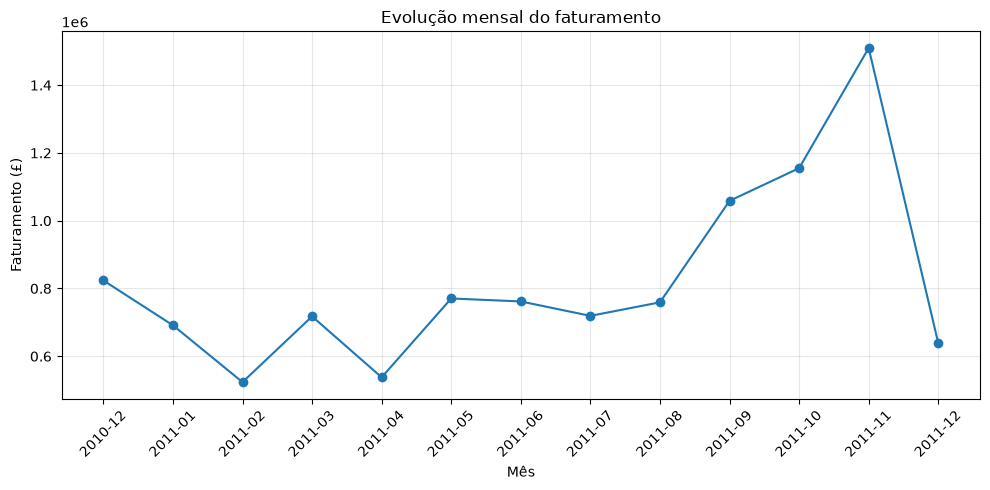

In [51]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index.astype(str), monthly["revenue"], marker="o")

ax.set_title("Evolução mensal do faturamento")
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento (£)")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Checagens para justificar os critérios
**1. Cancelamento é a mesma coisa que devolução?**
Verifico se existem linhas com quantidade negativa cuja fatura não começa com C.

In [32]:
negativa_sem_c = retail[retail["quantity"].lt(0) & ~retail["is_cancelled"]]
print(len(negativa_sem_c), "linhas com quantidade negativa sem fatura C")
negativa_sem_c.head()

1336 linhas com quantidade negativa sem fatura C


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,revenue,is_cancelled
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0,False
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,-0.0,False
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0,False
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0,False
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0,False


**2. Outlier é erro ou atacado legítimo?**
Olho as maiores quantidades junto com cliente e país, antes de descartar qualquer linha.

In [33]:
colunas_outlier = ["invoice_no", "description", "quantity", "unit_price", "customer_id", "country"]
retail.nlargest(10, "quantity")[colunas_outlier]

,invoice_no,description,quantity,unit_price,customer_id,country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,United Kingdom
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,United Kingdom
502122,578841,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,United Kingdom
74614,542504,NaN,5568,0.00,NaN,United Kingdom
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,United Kingdom
206121,554868,SMALL POPCORN HOLDER,4300,0.72,13135.0,United Kingdom
220843,556231,?,4000,0.00,NaN,United Kingdom
97432,544612,EMPIRE DESIGN ROSETTE,3906,0.82,18087.0,United Kingdom
270885,560599,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,14609.0,United Kingdom
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,15749.0,United Kingdom


**3. Qual recorte de vendas válidas defender?**
Existem linhas com preço zero e cliente ausente ao mesmo tempo?

In [34]:
zero_sem_cliente = retail[retail["unit_price"].eq(0) & retail["customer_id"].isna()]
print(len(zero_sem_cliente), "linhas com preco zero e sem customer_id")
zero_sem_cliente[["invoice_no", "description", "quantity", "country"]].head()

2475 linhas com preco zero e sem customer_id


,invoice_no,description,quantity,country
622,536414,NaN,56,United Kingdom
1970,536545,NaN,1,United Kingdom
1971,536546,NaN,1,United Kingdom
1972,536547,NaN,1,United Kingdom
1987,536549,NaN,1,United Kingdom


## Investigando os outliers
### Quantidades gigantes: venda real ou venda desfeita?
Antes de descartar as maiores quantidades, procuro um cancelamento do mesmo cliente, do mesmo produto e com a quantidade oposta.

In [ ]:
top10 = retail.nlargest(10, "quantity")

# cancelamentos com a quantidade trocada de sinal (para poder comparar com a venda original)
cancel_invertido = retail[retail["is_cancelled"]].assign(quantity=lambda d: -d["quantity"])

# merge: cruza as duas tabelas pelas colunas em comum; so sobram as vendas que tem cancelamento espelho
chave = ["customer_id", "stock_code", "quantity"]
revertidas = top10.merge(cancel_invertido[chave], on=chave)

print(f"Vendas grandes revertidas por cancelamento: {len(revertidas)}")
print(f"Faturamento dessas vendas: £ {revertidas['revenue'].sum():,.2f}")
revertidas[colunas_outlier]

In [ ]:
# tira da base de vendas validas as vendas que foram desfeitas
# merge com indicator=True cria a coluna _merge dizendo de que tabela veio cada linha
chave_venda = ["invoice_no", "stock_code", "quantity"]
sales_adj = sales.merge(revertidas[chave_venda], on=chave_venda, how="left", indicator=True)
sales_adj = sales_adj[sales_adj["_merge"] == "left_only"].drop(columns="_merge")

print(f"Faturamento bruto antes do ajuste: £ {sales['revenue'].sum():,.2f}")
print(f"Faturamento bruto depois do ajuste: £ {sales_adj['revenue'].sum():,.2f}")

### Preços gigantes: produtos ou lançamentos internos?
Olho os maiores preços unitários e os códigos de produto que não começam com dígito.

In [ ]:
retail.nlargest(10, "unit_price")[["invoice_no", "stock_code", "description", "quantity", "unit_price"]]

In [ ]:
# codigos de produto normais comecam com numero (ex.: 85123A); os outros sao taxas, frete e ajustes
# str.match("^\d") testa se o texto comeca com um digito; ~ inverte (os que NAO comecam)
nao_produto = retail[~retail["stock_code"].astype(str).str.match(r"^\d")]

(
    nao_produto
    .groupby("stock_code")
    .agg(linhas=("revenue", "size"), receita=("revenue", "sum"))
    .sort_values("linhas", ascending=False)
    .head(10)
    .round(2)
)

### Quantidade negativa sem fatura C
Se não são cancelamentos, o que são essas linhas?

In [ ]:
print("Preco zero:", negativa_sem_c["unit_price"].eq(0).sum())
print("Sem cliente:", negativa_sem_c["customer_id"].isna().sum())
negativa_sem_c["description"].value_counts().head(8)

### Produtos com maior faturamento depois dos ajustes

In [ ]:
# so produtos de verdade (codigo comeca com digito) e sem as vendas desfeitas
sales_prod = sales_adj[sales_adj["stock_code"].astype(str).str.match(r"^\d")]

products_adj = (
    sales_prod
    .dropna(subset=["description"])
    .groupby(["stock_code", "description"], as_index=False)
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        order_count=("invoice_no", "nunique"),
    )
)

products_adj.nlargest(10, "revenue").round(2)

## Evolução mensal ajustada
Mesmo cálculo mensal, agora sem as vendas desfeitas.

In [ ]:
monthly_adj = (
    sales_adj
    .assign(month=sales_adj["invoice_date"].dt.to_period("M"))
    .groupby("month")["revenue"]
    .sum()
)

monthly["revenue_ajustado"] = monthly_adj
monthly[["revenue", "revenue_ajustado"]].round(2)

## Concentração do faturamento
Quanto do faturamento depende de poucos países e clientes.

In [ ]:
total = sales_adj["revenue"].sum()

# participacao de cada pais no faturamento (div divide, mul multiplica, tudo em %)
share_country = (
    sales_adj.groupby("country")["revenue"].sum()
    .sort_values(ascending=False)
    .div(total).mul(100)
)
print("Participacao dos 5 maiores paises (%):")
print(share_country.head(5).round(1))

rev_customer = (
    sales_adj.dropna(subset=["customer_id"])
    .groupby("customer_id")["revenue"].sum()
    .sort_values(ascending=False)
)
top20 = int(len(rev_customer) * 0.2)

print(f"Top 10 clientes: {rev_customer.head(10).sum() / total * 100:.1f}% do faturamento")
print(f"Top 20% dos clientes: {rev_customer.head(top20).sum() / rev_customer.sum() * 100:.1f}% do faturamento identificado")
print(f"Faturamento sem cliente identificado: {sales_adj.loc[sales_adj['customer_id'].isna(), 'revenue'].sum() / total * 100:.1f}%")

In [ ]:
# ticket medio dentro e fora do Reino Unido
ticket_pais = (
    sales_adj.assign(uk=sales_adj["country"].eq("United Kingdom"))
    .groupby(["uk", "invoice_no"])["revenue"].sum()
    .groupby("uk").mean()
)
ticket_pais.round(2)

In [ ]:
# paises com ticket medio alto (minimo de 30 pedidos para a media ter sentido)
pedidos_pais = sales_adj.groupby(["country", "invoice_no"])["revenue"].sum().groupby("country").agg(["mean", "count"])
pedidos_pais[pedidos_pais["count"] >= 30].sort_values("mean", ascending=False).head(6).round(2)

## Critérios adotados

**Venda válida.** Linha de fatura que não começa com C, com `quantity > 0`, `unit_price > 0` e que não foi desfeita por um cancelamento do mesmo cliente, do mesmo produto e da mesma quantidade (base `sales_adj`).
- A letra C no número da fatura é a convenção do sistema para cancelamento (3.836 faturas).
- Preço zero aparece em 2.515 linhas e 2.475 delas não têm cliente, o que parece brinde ou ajuste interno e não venda.
- Três vendas grandes foram canceladas logo em seguida (as de 80.995, 74.215 e 3.114 unidades). Somam £ 252.192,60, cerca de 2,4% do faturamento bruto, e sem esse ajuste o faturamento ficaria inflado. O faturamento bruto cai de £ 10.666.684,54 para £ 10.414.491,94.

**Cancelamento.** Fatura com C. Todas têm quantidade negativa (nenhuma C com quantidade maior ou igual a zero). Representa o pedido desfeito pelo cliente, e seu valor entra no impacto financeiro.

**Devolução e ajuste.** Valor negativo que não é venda: as faturas C (£ 896.812,49) mais dois lançamentos "Adjust bad debt" de £ 11.062,06 cada, que fecham os £ 918.936,61 (8,6% do bruto original). Já as 1.336 linhas de quantidade negativa **sem** fatura C não são devoluções de clientes: todas têm preço zero e não têm cliente, com descrições como "check", "damages" e "thrown away". São baixas de estoque, então ficam fora do cálculo de devolução.

**Registro anômalo.**
- Códigos de produto que não começam com dígito (POST, DOT, M, AMAZONFEE, BANK CHARGES, D, S, CRUK): são frete, taxas e ajustes e não produtos. O DOT (frete do site) aparecia como o "produto" de maior faturamento, por isso ficaram fora do ranking de produtos (`products_adj`), mas continuam no faturamento total porque o frete também é receita.
- Preço negativo (2 linhas) e preço zero.
- Descrição ausente.
- Quantidades altas com cliente identificado e preço maior que zero foram mantidas como atacado, porque é um padrão esperado nesta base.
- As 5.268 duplicatas (0,97%) **não foram removidas**: o mesmo item pode aparecer duas vezes na mesma fatura e não dá para afirmar que é erro.

## Recomendações para a gestão comercial

1. **Reforçar estoque e campanhas de setembro a novembro.** Os três meses somam £ 3,72 milhões, 35,7% do faturamento ajustado, e novembro de 2011 (£ 1,51 milhão) é quase o dobro de agosto (£ 759 mil). Ressalva: só há um ciclo anual na base, e dezembro de 2011 é parcial (os dados terminam em 9/12).
2. **Criar um programa de retenção para os clientes de maior valor.** Os 20% maiores clientes geram 73,9% do faturamento identificado, e os 10 maiores respondem por 13,7% do total. Além disso, 16,9% do faturamento não tem cliente identificado, então vale tornar o cadastro do cliente obrigatório na venda.
3. **Expandir mercados fora do Reino Unido com ticket alto.** O Reino Unido concentra 84,2% do faturamento, mas o ticket médio fora dele é de £ 845,68, contra £ 486,93 dentro. Holanda (£ 3.036,66 por pedido) e Austrália (£ 2.430,20) lideram. Cuidado: esses países têm poucos clientes (a Holanda tem 9 e a Irlanda tem 3), então o resultado depende de poucos compradores.
4. **Atacar as causas dos cancelamentos.** 14,8% das faturas são canceladas (3.836 de 25.900) e as devoluções e ajustes equivalem a 8,6% do faturamento bruto original. Vale investigar quais produtos e clientes mais cancelam e checar o estoque, já que as 1.336 baixas de estoque sem cliente também indicam perdas.
5. **Priorizar os produtos que combinam faturamento e frequência.** Regency Cakestand 3 Tier (£ 174.484,74), White Hanging Heart T-Light Holder (£ 104.340,29 e o mais frequente, em 2.189 pedidos) e Party Bunting (£ 99.504,33). Os rankings devem ignorar códigos como DOT e POST, que são frete.
6. **Validar pedidos de quantidade muito alta antes de faturar.** Três das dez maiores quantidades foram canceladas logo depois. Uma conferência com o cliente evita contar receita que não vai se realizar e distorcer indicadores.

Observação sobre o ticket: a média (£ 534,40) é 76% maior que a mediana (£ 303,84), então poucos pedidos grandes puxam o indicador para cima, e a mediana descreve melhor o pedido típico.

In [ ]:
# commit que encerra a sessao (salve o notebook antes)
!git add Unidade_01/aula_pratica_02/exercicio_aula_03.ipynb
!git commit -m "Adiciona analise de vendas da aula 3"
!git log --oneline